# Análise dos patches de deduplicação (TechDebt 2027)

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Dados

Extrai na mão as infos da tabela em ` papers/techdebt2027/techdebt.tex`

In [22]:
rows = [
    # year, gid, ss, sml, status, technique, added, removed
    (2025, 0,  "AMD", 100, "Accepted (v4)", "Pull Up Method", 114, 520),
    (2025, 1,  "AMD",  90, "Accepted (v2)", "Pull Up Method", 90, 489),
    (2025, 1,  "IIO", 100, "Rejected (v1)", "Inline Method", 2, 12),
    (2025, 2,  "IIO", 100, "Rejected (v2)", "Extract Method", 7, 14),
    (2025, 3,  "IIO", 100, "Rejected (v1)", "Parameterize Method", 23, 27),
    (2025, 4,  "IIO", 100, "Accepted (v1)", "Parameterize Method", 12, 30),
    (2025, 5,  "IIO", 100, "Accepted (v3)", "Substitute Algorithm", 2, 7),
    (2025, 6,  "IIO",  90, "Accepted (v1)", "Parameterize Method", 17, 70),
    (2025, 7,  "IIO",  90, "Rejected (v1)", "Parameterize Method", 95, 92),
    (2025, 8,  "IIO",  90, "Accepted (v3)", "Extract Method",  0, 36),
    (2025, 9,  "IIO",  90, "Accepted (v4)", "Extract Method", 20, 16),
    (2025, 10, "IIO",  90, "Accepted (v6)", "Replace Inline Code with Function Call", 149, 243),
    (2025, 11, "IIO",  90, "Rejected (v1)", "Substitute Algorithm",32, 58),
    (2026, 0,  "AMD", 100, "No response",   "Extract Method", 86, 114),
    (2026, 0,  "IIO", 100, "Accepted (v1)", "Substitute Algorithm",15, 32),
    (2026, 0,  "IIO", 100, "Accepted (v4)", "Substitute Algorithm",71,119),
    (2026, 0,  "AMD",  90, "Accepted (v1)", "Substitute Algorithm", 1274, 2035),
    (2026, 0,  "AMD", 100, "Accepted (v3)", "Extract Method", 41, 124),
    (2026, 1,  "AMD", 100, "Accepted (v2)", "Replace Inline Code with Function Call", 12, 61),
    (2026, 2,  "AMD", 100, "Accepted (v2)", "Replace Inline Code with Function Call", 13, 42),
    (2026, 3,  "AMD", 100, "Rejected (v1)", "Extract Method", 61, 94),
    (2026, 4,  "AMD", 100, "Accepted (v4)", "Extract Method", 56,102),
    (2026, 5,  "IIO", 100, "Accepted (v4)", "Substitute Algorithm",29, 66),
    (2026, 6,  "IIO", 100, "Accepted (v4)", "Inline Method", 42, 88),
    (2026, 7,  "AMD", 100, "Rejected (v1)", "Extract Method", 31, 190),
    (2026, 8,  "AMD", 100, "No response", "Extract Method", 42, 75),
    (2026, 9,  "AMD", 100, "Accepted (v6)", "Extract Method", 54, 80),
    (2026, 10, "AMD", 100, "Rejected (v1)", "Pull Up Method", 47,124),
    (2026, 11, "IIO",  90, "Rejected (v1)", "Parameterize Method", 62, 68),
    (2026, 12, "IIO",  90, "Dropped (v2)",  "Parameterize Method", 42, 60),
]

columns = ["year", "gid", "ss", "sml", "status", "technique", "added", "removed"]
df = pd.DataFrame(rows, columns=columns)
df

,year,gid,ss,sml,status,technique,added,removed
0,2025,0,AMD,100,Accepted (v4),Pull Up Method,114,520
1,2025,1,AMD,90,Accepted (v2),Pull Up Method,90,489
2,2025,1,IIO,100,Rejected (v1),Inline Method,2,12
3,2025,2,IIO,100,Rejected (v2),Extract Method,7,14
4,2025,3,IIO,100,Rejected (v1),Parameterize Method,23,27
5,2025,4,IIO,100,Accepted (v1),Parameterize Method,12,30
6,2025,5,IIO,100,Accepted (v3),Substitute Algorithm,2,7
7,2025,6,IIO,90,Accepted (v1),Parameterize Method,17,70
8,2025,7,IIO,90,Rejected (v1),Parameterize Method,95,92
9,2025,8,IIO,90,Accepted (v3),Extract Method,0,36


### Colunas derivadas

- `result`: status sem a versão (Accepted, Rejected, Dropped, No response)
- `version`: número da versão do patch (`v4` → 4); *No response* fica vazio
- `accepted`: 1 se aceito, 0 caso contrário
- `net`: linhas removidas − linhas adicionadas (redução líquida)
- `net_pct`: redução líquida (%)
- `churn`: linhas adicionadas + removidas (tamanho do patch)

In [23]:
df["result"] = df["status"].str.split(" (", regex=False).str[0]
df["version"] = df["status"].str.extract(r"v(\d+)")[0].astype(float)
df["accepted"] = (df["result"] == "Accepted").astype(int)
df["net"] = df["removed"] - df["added"]
df["churn"] = df["added"] + df["removed"]
df["net_pct"] = (100 * df["net"] / df["churn"]).round(2)


df[["year", "gid", "ss", "result", "version", "technique", "added", "removed", "net", "net_pct"]]

,year,gid,ss,result,version,technique,added,removed,net,net_pct
0,2025,0,AMD,Accepted,4.0,Pull Up Method,114,520,406,64.04
1,2025,1,AMD,Accepted,2.0,Pull Up Method,90,489,399,68.91
2,2025,1,IIO,Rejected,1.0,Inline Method,2,12,10,71.43
3,2025,2,IIO,Rejected,2.0,Extract Method,7,14,7,33.33
4,2025,3,IIO,Rejected,1.0,Parameterize Method,23,27,4,8.00
5,2025,4,IIO,Accepted,1.0,Parameterize Method,12,30,18,42.86
6,2025,5,IIO,Accepted,3.0,Substitute Algorithm,2,7,5,55.56
7,2025,6,IIO,Accepted,1.0,Parameterize Method,17,70,53,60.92
8,2025,7,IIO,Rejected,1.0,Parameterize Method,95,92,-3,-1.60
9,2025,8,IIO,Accepted,3.0,Extract Method,0,36,36,100.00


## 2. Visão geral

In [24]:
n = len(df)
n_acc = df["accepted"].sum()
acc = df[df["accepted"] == 1]

print(f"Patches:                                                {n}")
print(f"Patches aceitos:                                    {n_acc} ({100 * n_acc / n:.1f}%)")
print(f"Linhas adicionadas:                               {df['added'].sum()}")
print(f"Linhas removidas:                                 {df['removed'].sum()}")
print(f"Redução líquida (todos):                       {df['net'].sum()} linhas")
print(f"Redução líquida (aceitos):                     {acc['net'].sum()} linhas")
print(f"Patches que aumentaram o código:     {(df['net'] < 0).sum()}")

outlier = df.loc[df["removed"].idxmax()]

percentage = 100 * outlier["net"] / acc["net"].sum()
print(f"\n\nTem um patch muito grande que é basicamente um outlier")
print(f"Esse patch corresponde a {percentage:.2f}% da redução aceita ({outlier["net"]} linhas).")

Patches:                                                30
Patches aceitos:                                    18 (60.0%)
Linhas adicionadas:                               2541
Linhas removidas:                                 5088
Redução líquida (todos):                       2547 linhas
Redução líquida (aceitos):                     2149 linhas
Patches que aumentaram o código:     2


Tem um patch muito grande que é basicamente um outlier
Esse patch corresponde a 35.41% da redução aceita (761 linhas).


## 3. Status dos patches

In [25]:
status = df["result"].value_counts().to_frame("patches")
status["%"] = (100 * status["patches"] / n).round(2)
status

,patches,%
result,,
Accepted,18,60.00
Rejected,9,30.00
No response,2,6.67
Dropped,1,3.33


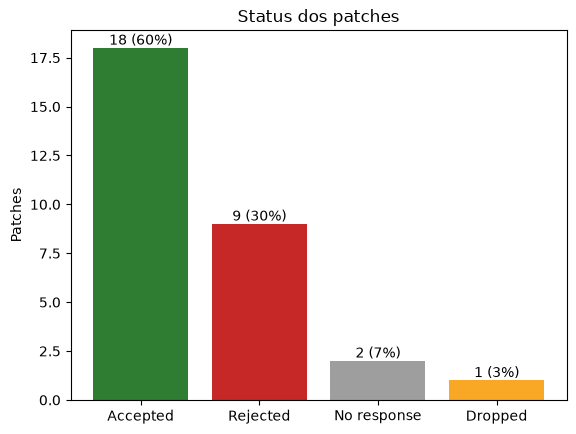

In [26]:
colors = {"Accepted": "#2e7d32", "Rejected": "#c62828",
          "Dropped": "#f9a825", "No response": "#9e9e9e"}

fig, ax = plt.subplots()
bars = ax.bar(status.index, status["patches"],
              color=[colors[s] for s in status.index])
ax.bar_label(bars, labels=[f"{c} ({p:.0f}%)" for c, p in zip(status["patches"], status["%"])])
ax.set_ylabel("Patches")
ax.set_title("Status dos patches")
plt.show()

## 4. Técnicas de refatoração mais usadas

In [27]:
tech = df["technique"].value_counts().to_frame("patches")
tech["%"] = (100 * tech["patches"] / n).round(2)
tech

,patches,%
technique,,
Extract Method,10,33.33
Parameterize Method,6,20.00
Substitute Algorithm,6,20.00
Pull Up Method,3,10.00
Replace Inline Code with Function Call,3,10.00
Inline Method,2,6.67


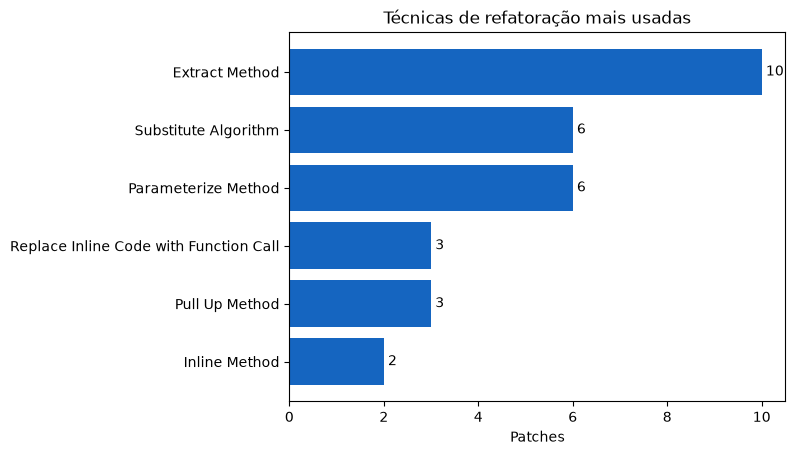

In [28]:
fig, ax = plt.subplots()
t = tech.sort_values("patches")
bars = ax.barh(t.index, t["patches"], color="#1565c0")
ax.bar_label(bars, padding=3)
ax.set_xlabel("Patches")
ax.set_title("Técnicas de refatoração mais usadas")
plt.show()

## 5. Aceitação

In [29]:
tech_status = pd.crosstab(df["technique"], df["result"])
tech_status["total"] = tech_status.sum(axis=1)
tech_status["acceptance %"] = (100 * tech_status["Accepted"] / tech_status["total"]).round(2)
tech_status = tech_status.sort_values(["acceptance %", "total"], ascending=False)
tech_status

result,Accepted,Dropped,No response,Rejected,total,acceptance %
technique,,,,,,
Replace Inline Code with Function Call,3,0,0,0,3,100.00
Substitute Algorithm,5,0,0,1,6,83.33
Pull Up Method,2,0,0,1,3,66.67
Extract Method,5,0,2,3,10,50.00
Inline Method,1,0,0,1,2,50.00
Parameterize Method,2,1,0,3,6,33.33


Essa aceitação de 100% é pouco confiável por ser apenas 2 e 3 patches

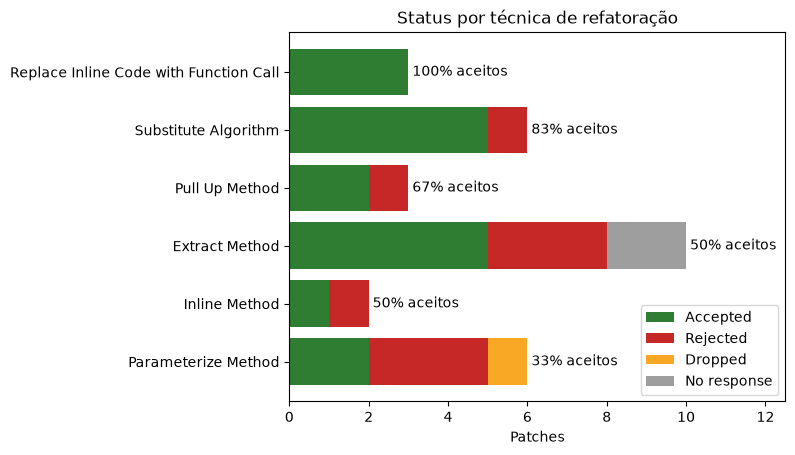

In [30]:
order = ["Accepted", "Rejected", "Dropped", "No response"]
t = tech_status[order].iloc[::-1]

fig, ax = plt.subplots()
left = np.zeros(len(t))
for s in order:
    ax.barh(t.index, t[s], left=left, color=colors[s], label=s)
    left = left + t[s].values
for i, p in enumerate(tech_status["acceptance %"].iloc[::-1]):
    ax.text(left[i] + 0.1, i, f"{p:.0f}% aceitos", va="center")
ax.set_xlim(0, left.max() + 2.5)
ax.set_xlabel("Patches")
ax.set_title("Status por técnica de refatoração")
ax.legend(loc="lower right")
plt.show()

## 6. Redução de linhas por técnica

In [31]:
tech_lines = df.groupby("technique").agg(
    patches=("net", "count"), # qtd patches
    added=("added", "sum"), # qtd adicionados
    removed=("removed", "sum"), # qtd removidos
    net_total=("net", "sum"), # Total das remoções liquidas
    net_mean=("net", "mean"), # Media || 
    net_median=("net", "median"), # Mediana || 
    net_pct_mean=("net_pct", "mean"), # 
)
tech_lines.sort_values("net_total", ascending=False)

,patches,added,removed,net_total,net_mean,net_median,net_pct_mean
technique,,,,,,,
Substitute Algorithm,6,1423,2317,894,149.000000,31.5,34.638333
Pull Up Method,3,251,1133,882,294.000000,399.0,59.326667
Extract Method,10,398,845,447,44.700000,33.0,35.648000
Replace Inline Code with Function Call,3,174,346,172,57.333333,49.0,47.943333
Parameterize Method,6,251,347,96,16.000000,12.0,22.075000
Inline Method,2,44,100,56,28.000000,28.0,53.405000


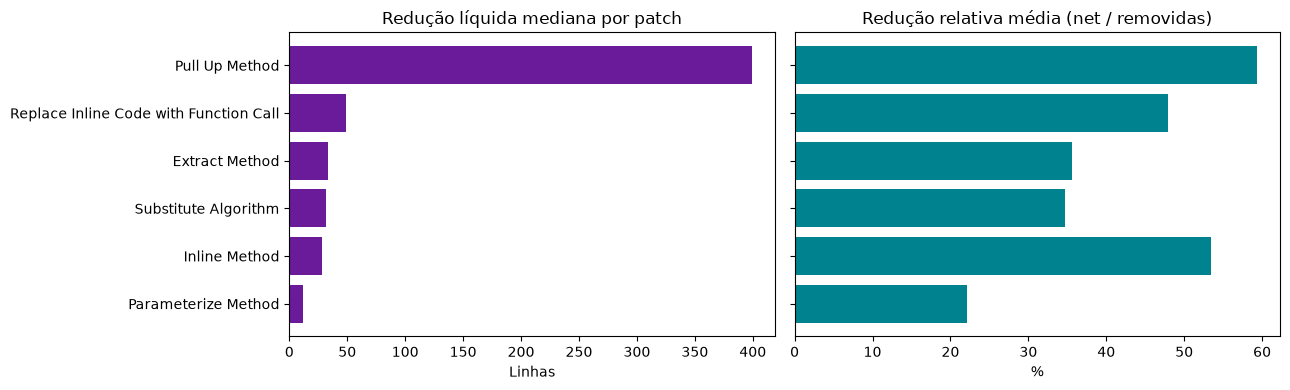

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

t = tech_lines.sort_values("net_median")
axes[0].barh(t.index, t["net_median"], color="#6a1b9a")
axes[0].set_xlabel("Linhas")
axes[0].set_title("Redução líquida mediana por patch")

axes[1].barh(t.index, t["net_pct_mean"], color="#00838f")
axes[1].set_xlabel("%")
axes[1].set_title("Redução relativa média (net / removidas)")

plt.tight_layout()
plt.show()

### Sem o outlier

In [33]:
outlier = df["removed"] == df["removed"].max()
df_no_out = df[~outlier]

df_no_out = df_no_out.groupby("technique").agg(
    patches=("net", "size"),
    net_total=("net", "sum"),
    net_mean=("net", "mean"),
    net_median=("net", "median"),
    net_pct_mean=("net_pct", "mean"),
).sort_values("net_total", ascending=False)
df_no_out

,patches,net_total,net_mean,net_median,net_pct_mean
technique,,,,,
Pull Up Method,3,882,294.000000,399.0,59.326667
Extract Method,10,447,44.700000,33.0,35.648000
Replace Inline Code with Function Call,3,172,57.333333,49.0,47.943333
Substitute Algorithm,5,133,26.600000,26.0,36.966000
Parameterize Method,6,96,16.000000,12.0,22.075000
Inline Method,2,56,28.000000,28.0,53.405000


In [34]:
""" fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

q = df_no_out.sort_values("net_median")
axes[0].barh(q.index, q["net_median"], color="#6a1b9a")
axes[0].set_xlabel("Linhas")
axes[0].set_title("Redução líquida mediana por patch")

axes[1].barh(q.index, q["net_pct_mean"], color="#00838f")
axes[1].set_xlabel("%")
axes[1].set_title("Redução relativa média (net / removidas)")

plt.tight_layout()
plt.show() """

' fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)\n\nq = df_no_out.sort_values("net_median")\naxes[0].barh(q.index, q["net_median"], color="#6a1b9a")\naxes[0].set_xlabel("Linhas")\naxes[0].set_title("Redução líquida mediana por patch")\n\naxes[1].barh(q.index, q["net_pct_mean"], color="#00838f")\naxes[1].set_xlabel("%")\naxes[1].set_title("Redução relativa média (net / removidas)")\n\nplt.tight_layout()\nplt.show() '

## 9. Versões até o aceite


In [35]:
df.groupby("result")["version"].describe()

,count,mean,std,min,25%,50%,75%,max
result,,,,,,,,
Accepted,18.0,3.055556,1.589385,1.0,2.0,3.0,4.0,6.0
Dropped,1.0,2.000000,NaN,2.0,2.0,2.0,2.0,2.0
No response,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rejected,9.0,1.111111,0.333333,1.0,1.0,1.0,1.0,2.0


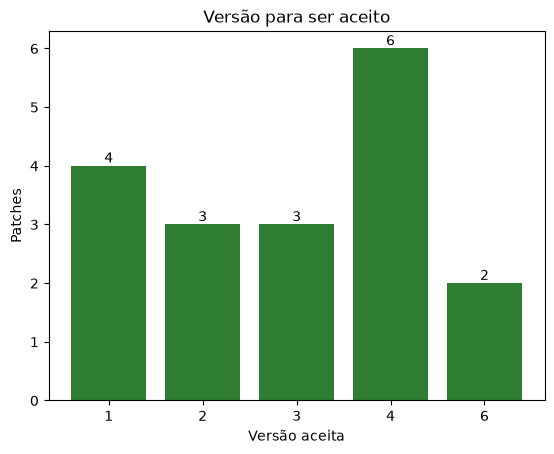

Aceitos na v1:      4 de 18
Média de versões:   3.06
Mediana de versões: 3


In [36]:
acc = df[df["accepted"] == 1]
versions = acc["version"].value_counts().sort_index()

fig, ax = plt.subplots()
bars = ax.bar(versions.index.astype(int).astype(str), versions.values, color="#2e7d32")
ax.bar_label(bars)
ax.set_xlabel("Versão aceita")
ax.set_ylabel("Patches")
ax.set_title("Versão para ser aceito")
plt.show()

print(f"Aceitos na v1:      {(acc['version'] == 1).sum()} de {len(acc)}")
print(f"Média de versões:   {acc['version'].mean():.2f}")
print(f"Mediana de versões: {acc['version'].median():.0f}")

In [37]:
# número médio de versões até o aceite, por técnica
acc.groupby("technique")["version"].agg(["count", "mean", "min", "max"]).sort_values("mean")

,count,mean,min,max
technique,,,,
Parameterize Method,2,1.000000,1.0,1.0
Substitute Algorithm,5,2.600000,1.0,4.0
Pull Up Method,2,3.000000,2.0,4.0
Replace Inline Code with Function Call,3,3.333333,2.0,6.0
Extract Method,5,4.000000,3.0,6.0
Inline Method,1,4.000000,4.0,4.0


## 10. O tamanho do patch influencia

In [38]:
df["accepted_label"] = np.where(df["accepted"] == 1, "Aceito", "Não aceito")
df.groupby("accepted_label")[["added", "removed", "churn", "net", "net_pct"]].median()

,added,removed,churn,net,net_pct
accepted_label,,,,,
Aceito,35.0,75.0,112.5,46.0,40.905
Não aceito,42.0,71.5,123.5,22.0,24.750


## 12. Geral

In [39]:
final = pd.DataFrame({
    "patches": tech_status["total"],
    "uso %": 100 * tech_status["total"] / n,
    "aceitos": tech_status["Accepted"],
    "aceitação %": tech_status["acceptance %"],
    "redução total": tech_lines["net_total"],
    "redução mediana": tech_lines["net_median"],
    "redução relativa média %": tech_lines["net_pct_mean"],
    "versões até aceite (média)": acc.groupby("technique")["version"].mean(),
}).sort_values("patches", ascending=False)
final

,patches,uso %,aceitos,aceitação %,redução total,redução mediana,redução relativa média %,versões até aceite (média)
technique,,,,,,,,
Extract Method,10,33.333333,5,50.00,447,33.0,35.648000,4.000000
Parameterize Method,6,20.000000,2,33.33,96,12.0,22.075000,1.000000
Substitute Algorithm,6,20.000000,5,83.33,894,31.5,34.638333,2.600000
Pull Up Method,3,10.000000,2,66.67,882,399.0,59.326667,3.000000
Replace Inline Code with Function Call,3,10.000000,3,100.00,172,49.0,47.943333,3.333333
Inline Method,2,6.666667,1,50.00,56,28.0,53.405000,4.000000


In [40]:
# versão LaTeX da tabela
# print(final.to_latex(float_format="%.1f"))

## 13. Observações parciais:

Depois dessa correção eu nn cheguei a fazer uma analise melhor

